# 13 · Main figures

The six main figures are assembled from the result tables written by
Notebooks 01–12 (`results/tables/`) and two AnnData files (UMAP coordinates
and fate probabilities). Nothing is recomputed: the figures can be restyled
without rerunning any analysis. Every figure is 183 mm wide (Nature double
column) and saved as SVG, JPG and PNG at 300 dpi in `results/figures/13_main/`;
the legends are in `docs/figures.md`.

| Figure | Content | Source notebooks |
|---|---|---|
| 1 | cohorts, QC and the discovery atlas | 01, 02, 04, 05, 06 |
| 2 | cell-type composition in IPF | 06 |
| 3 | differential expression, pathways and transcription factors | 07, 08, 12 |
| 4 | the alveolar epithelial trajectory to aberrant basaloid cells | 09 |
| 5 | cell–cell communication | 10 |
| 6 | replication in an independent cohort | 12 |

In [1]:
import textwrap

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from adjustText import adjust_text
from matplotlib import patheffects
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.metrics import roc_auc_score, roc_curve

from ipfatlas.config import setup
from ipfatlas.plotting import (
    COMPARTMENT_COLORS,
    CONDITION_COLORS,
    LINEAGE_COLORS,
    SITE_COLORS,
    embedding_scatter,
    figsize,
    label_centroids,
    panel_labels,
    save_figure,
    set_style,
    umap_axis_arrows,
)

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "13_main"
W = cfg["figures"]["double_column_mm"]
COMPARTMENTS = ["Epithelial", "Immune", "Endothelial", "Mesenchymal"]
DX = ["Control", "IPF", "NSIP", "cHP", "Sarcoidosis", "ILD"]


def tab(name: str, **kw) -> pd.DataFrame:
    return pd.read_csv(P.tables / f"{name}.csv", **kw)


def thousands(ax, axis="x"):
    fmt = mpl.ticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k" if v else "0")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)


def fmt_p(p: float) -> str:
    """P value for a title: 0.03, or 7 × 10⁻⁵ below 0.001 (mathtext exponent; Arial has no superscript minus)."""
    if p >= 0.001:
        return f"{p:.2g}"
    m, e = f"{p:.0e}".split("e")
    return f"{m} × 10$^{{\\mathregular{{{int(e)}}}}}$"


# atlas labels, colours and UMAP (obs and obsm only: the expression matrix is not loaded)
disc = ad.read_h5ad(P.processed / "discovery_annotated.h5ad", backed="r")
obs = disc.obs[["donor_id", "diagnosis", "cell_type", "compartment"]].copy()
umap = np.asarray(disc.obsm["X_umap"])
colors = dict(zip(obs["cell_type"].cat.categories, disc.uns["cell_type_colors"]))
disc.file.close()
comp_of = obs.groupby("cell_type", observed=True)["compartment"].first().astype(str)
grouped = [t for c in COMPARTMENTS for t in obs["cell_type"].cat.categories if comp_of[t] == c]
print(f"{len(obs):,} cells, {len(grouped)} cell types")

132,455 cells, 36 cell types


## Figure 1 · Cohorts, quality control and the discovery atlas

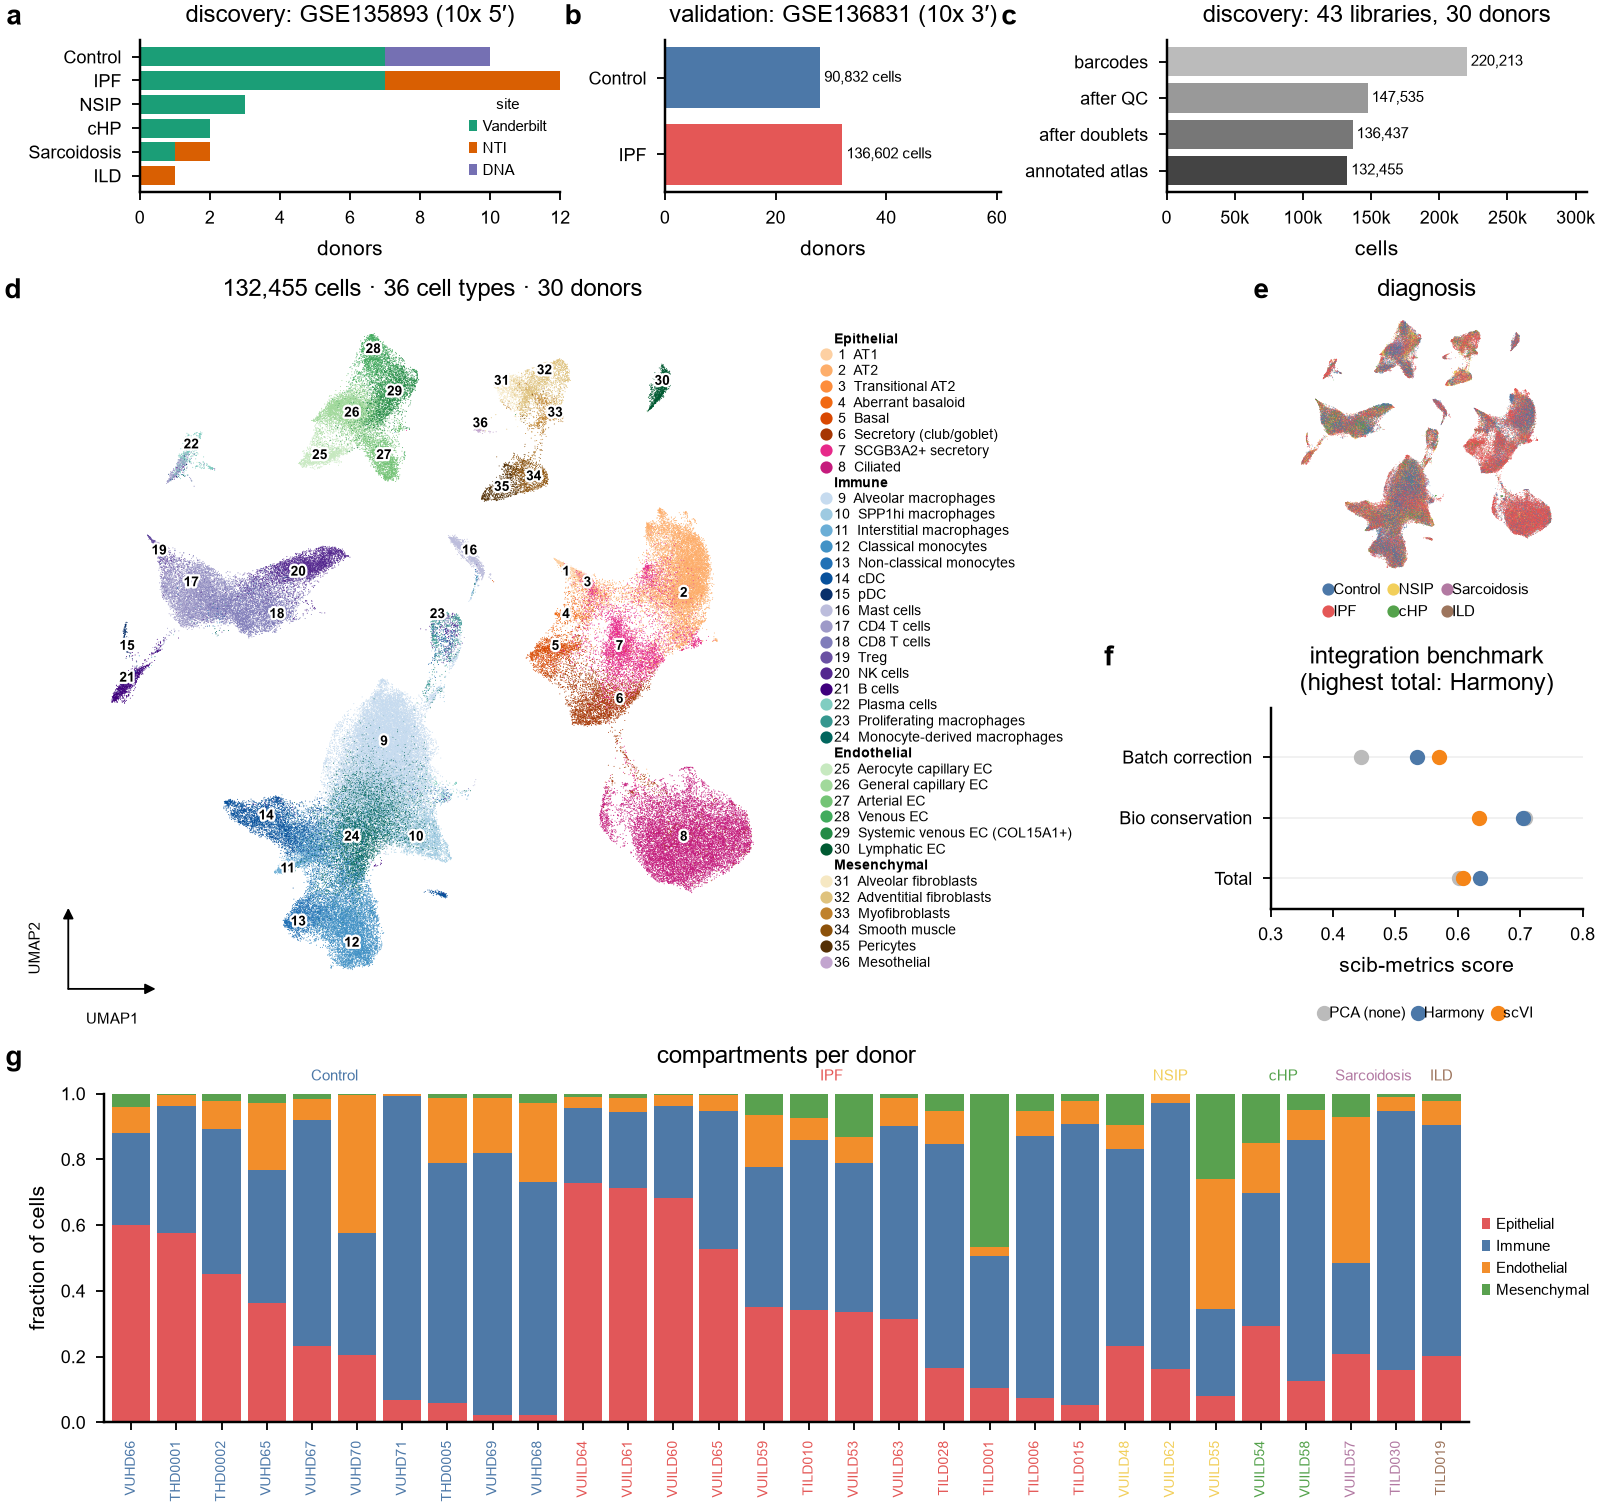

In [2]:
lib = tab("01_data/discovery_libraries")
donors = lib.drop_duplicates("donor_id").set_index("donor_id")
design = pd.crosstab(donors["diagnosis"], donors["site"]).reindex(DX).fillna(0)
vsum = tab("11_validation/validation_cohort_summary").set_index("diagnosis")
flow = tab("02_qc/qc_cell_flow", index_col=0)["value"]
bench = tab("04_integration/scib_metrics_benchmark").set_index("Embedding").drop(index="Metric Type").astype(float)
props = tab("06_composition/cell_type_proportions_per_donor", index_col=0)
comp_props = props.T.groupby(comp_of.reindex(props.columns)).sum().T[COMPARTMENTS]

fig = plt.figure(figsize=figsize(W, 175), layout="constrained")
gs = fig.add_gridspec(3, 1, height_ratios=[0.75, 2.1, 0.9])
top = gs[0].subgridspec(1, 3, width_ratios=[1, 0.8, 1])
mid = gs[1].subgridspec(1, 3, width_ratios=[1.4, 0.55, 0.95])
right = mid[2].subgridspec(2, 1, height_ratios=[1.3, 1])
ax_a, ax_b, ax_c = (fig.add_subplot(top[i]) for i in range(3))
ax_d, ax_key = fig.add_subplot(mid[0]), fig.add_subplot(mid[1])
ax_e, ax_f = fig.add_subplot(right[0]), fig.add_subplot(right[1])
ax_g = fig.add_subplot(gs[2])

left = np.zeros(len(design))
for site in ["Vanderbilt", "NTI", "DNA"]:
    ax_a.barh(design.index, design[site], left=left, color=SITE_COLORS[site], label=site)
    left += design[site].to_numpy()
ax_a.invert_yaxis()
ax_a.set_xlabel("donors")
ax_a.set_title("discovery: GSE135893 (10x 5′)")
ax_a.legend(title="site", fontsize=5, title_fontsize=5, frameon=False, loc="lower right")

ax_b.barh(vsum.index, vsum["donors"], color=[CONDITION_COLORS[d] for d in vsum.index])
for i, r in enumerate(vsum.itertuples()):
    ax_b.text(r.donors + 0.8, i, f"{r.cells:,} cells", va="center", fontsize=5)
ax_b.invert_yaxis()
ax_b.set_xlim(0, vsum["donors"].max() * 1.9)
ax_b.set_xlabel("donors")
ax_b.set_title("validation: GSE136831 (10x 3′)")

steps = pd.Series({"barcodes": flow["barcodes (Cell Ranger)"], "after QC": flow["after MAD/hard QC"],
                   "after doublets": flow["after doublet removal"], "annotated atlas": len(obs)})
ax_c.barh(steps.index, steps.to_numpy(), color=["#BBBBBB", "#999999", "#777777", "#444444"])
for i, v in enumerate(steps.to_numpy()):
    ax_c.text(v, i, f" {v:,}", va="center", fontsize=5)
ax_c.invert_yaxis()
ax_c.set_xlim(0, steps.max() * 1.4)
thousands(ax_c)
ax_c.set_xlabel("cells")
ax_c.set_title(f"discovery: {int(flow['libraries'])} libraries, {int(flow['donors'])} donors")

embedding_scatter(ax_d, umap, obs["cell_type"], palette=colors, s=0.1)
numbers = label_centroids(ax_d, umap, obs["cell_type"], fontsize=4.5, min_cells=1, numbered=True, order=grouped)
umap_axis_arrows(ax_d)
ax_d.set_title(f"{len(obs):,} cells · {len(grouped)} cell types · {obs['donor_id'].nunique()} donors")
handles = []
for comp in COMPARTMENTS:
    handles.append(plt.Line2D([], [], ls="", label=comp))
    handles += [plt.Line2D([], [], marker="o", ls="", color=colors[t], markersize=3, label=f"{numbers[t]:>2}  {t}")
                for t in grouped if comp_of[t] == comp]
ax_key.axis("off")
key = ax_key.legend(handles=handles, loc="center left", frameon=False, fontsize=4.5, handletextpad=0.2,
                    labelspacing=0.2, handlelength=0.8, borderaxespad=0)
for txt in key.get_texts():
    if txt.get_text() in COMPARTMENTS:
        txt.set_fontweight("bold")

embedding_scatter(ax_e, umap, obs["diagnosis"], palette=CONDITION_COLORS, s=0.05)
ax_e.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=CONDITION_COLORS[d], ms=3, label=d)
                     for d in DX if d in set(obs["diagnosis"])],
            fontsize=5, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 0.02), handletextpad=0.1,
            columnspacing=0.6)
ax_e.set_title("diagnosis")

b = bench[["Batch correction", "Bio conservation", "Total"]].rename(index=lambda s: s.replace("X_", "").replace(
    "pca", "PCA (none)").replace("harmony", "Harmony"))
yy = np.arange(b.shape[1])
for j, (name, row) in enumerate(b.iterrows()):
    ax_f.scatter(row.to_numpy(), yy, s=16, color=["#BBBBBB", "#4C78A8", "#F58518"][j], label=name, zorder=3)
ax_f.hlines(yy, 0.3, 0.8, color="#EEEEEE", lw=0.5, zorder=0)
ax_f.set_yticks(yy, b.columns)
ax_f.set_ylim(len(yy) - 0.5, -0.8)
ax_f.set_xlim(0.3, 0.8)
ax_f.set_xlabel("scib-metrics score")
ax_f.set_title(f"integration benchmark\n(highest total: {b['Total'].idxmax()})")
ax_f.legend(fontsize=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.42), ncol=3,
            handletextpad=0.1, columnspacing=0.6)

cp = comp_props.assign(dx=pd.Categorical(donors["diagnosis"].reindex(comp_props.index), DX))
cp = cp.sort_values(["dx", "Epithelial"], ascending=[True, False])
x = np.arange(len(cp))
bottom = np.zeros(len(cp))
for comp in COMPARTMENTS:
    ax_g.bar(x, cp[comp], bottom=bottom, width=0.85, color=COMPARTMENT_COLORS[comp], label=comp)
    bottom += cp[comp].to_numpy()
ax_g.set_xticks(x, cp.index, rotation=90, fontsize=4.5)
for lab_, d in zip(ax_g.get_xticklabels(), cp["dx"]):
    lab_.set_color(CONDITION_COLORS[d])
for d, idx in cp.groupby("dx", observed=True).indices.items():
    ax_g.text(idx.mean(), 1.03, d, ha="center", va="bottom", fontsize=5, color=CONDITION_COLORS[d])
ax_g.set_xlim(-0.6, len(cp) - 0.4)
ax_g.set_ylim(0, 1)
ax_g.set_ylabel("fraction of cells")
ax_g.set_title("compartments per donor", pad=10)
ax_g.legend(fontsize=5, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
panel_labels(fig, [ax_a, ax_b, ax_c, ax_d, ax_e, ax_f, ax_g], "abcdefg")
save_figure(fig, "Fig1_cohorts_atlas", FIG)
plt.show()

## Figure 2 · Cell-type composition in IPF
Panels a and b share the cell-type order (log2 ratio of mean proportions,
propeller within compartment); filled markers are robust shifts (propeller FDR
< 0.05 and credible in scCODA).

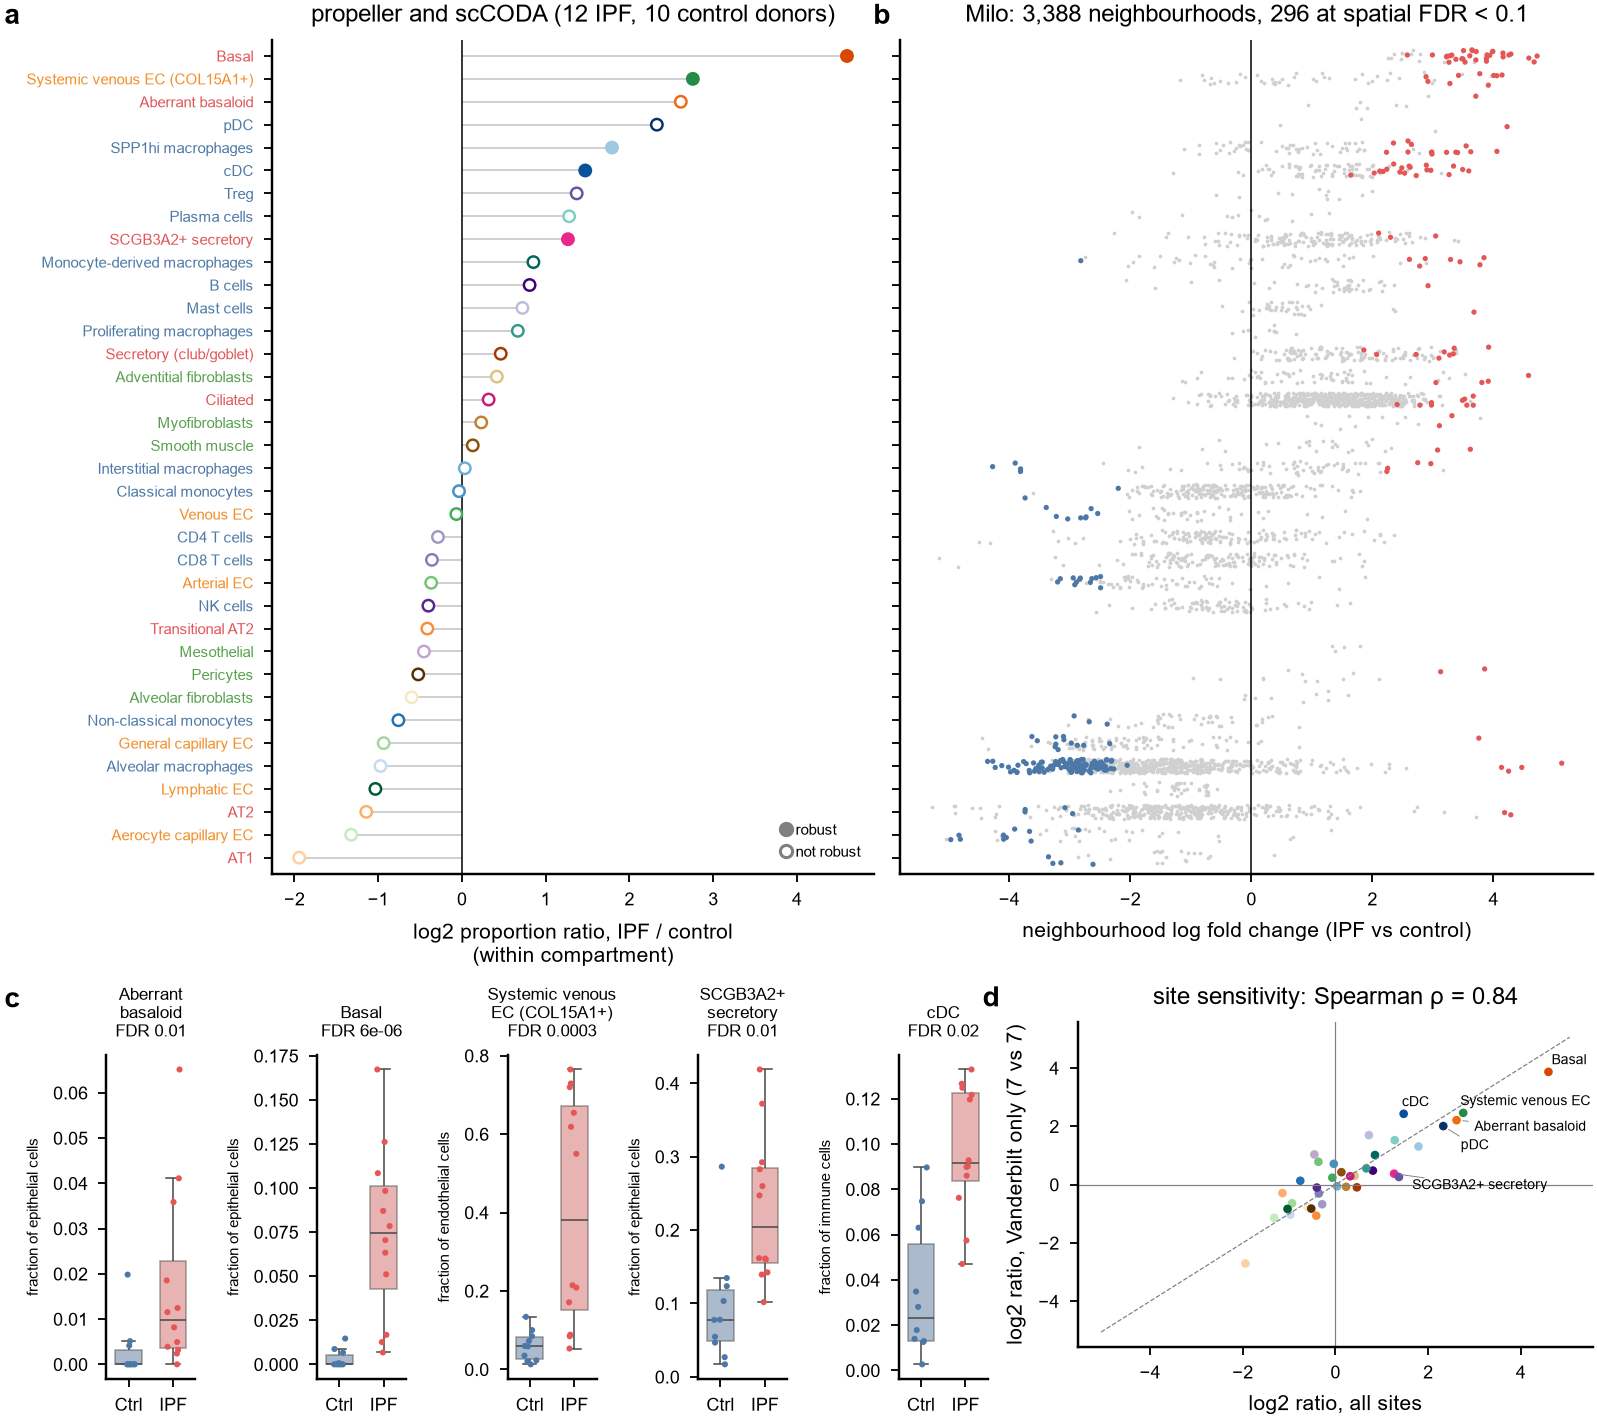

In [3]:
cons = tab("06_composition/composition_consensus").sort_values("log2_prop_ratio")
milo = tab("06_composition/milo_neighbourhoods", index_col=0)
milo = milo[(milo["nhood_annotation_frac"] >= 0.6) & milo["nhood_annotation"].isin(cons["celltype"])]
vu = tab("06_composition/composition_sensitivity_vanderbilt")
pos = {t: i for i, t in enumerate(cons["celltype"])}

fig = plt.figure(figsize=figsize(W, 165), layout="constrained")
gs = fig.add_gridspec(2, 1, height_ratios=[2.2, 1])
top = gs[0].subgridspec(1, 2, width_ratios=[1, 1.15])
bot = gs[1].subgridspec(1, 2, width_ratios=[1.9, 1])
ax_a, ax_b = fig.add_subplot(top[0]), fig.add_subplot(top[1])

yy = np.arange(len(cons))
ccol = [colors[t] for t in cons["celltype"]]
ax_a.hlines(yy, 0, cons["log2_prop_ratio"], color="#CCCCCC", lw=0.6)
ax_a.scatter(cons["log2_prop_ratio"], yy, s=14, c=np.where(cons["robust"], ccol, "white"), edgecolor=ccol, lw=0.8,
             zorder=3)
ax_a.axvline(0, lw=0.5, color="black")
ax_a.set_yticks(yy, cons["celltype"], fontsize=5)
for lab_, t in zip(ax_a.get_yticklabels(), cons["celltype"]):
    lab_.set_color(COMPARTMENT_COLORS[comp_of[t]])
ax_a.set_ylim(-0.7, len(cons) - 0.3)
ax_a.set_xlabel("log2 proportion ratio, IPF / control\n(within compartment)")
n_dx = donors["diagnosis"].value_counts()
ax_a.set_title(f"propeller and scCODA ({n_dx['IPF']} IPF, {n_dx['Control']} control donors)")
ax_a.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=4, mfc="grey", mec="grey", label="robust"),
                     plt.Line2D([], [], marker="o", ls="", ms=4, mfc="white", mec="grey", label="not robust")],
            fontsize=5, frameon=False, loc="lower right")

rng = np.random.default_rng(0)
sig = milo["SpatialFDR"] < 0.1
y = milo["nhood_annotation"].map(pos).to_numpy() + rng.uniform(-0.3, 0.3, len(milo))
ax_b.scatter(milo.loc[~sig, "logFC"], y[~sig], s=1.5, color="#D0D0D0", lw=0, rasterized=True)
ax_b.scatter(milo.loc[sig, "logFC"], y[sig], s=3, lw=0, rasterized=True,
             color=np.where(milo.loc[sig, "logFC"] > 0, CONDITION_COLORS["IPF"], CONDITION_COLORS["Control"]))
ax_b.axvline(0, lw=0.5, color="black")
ax_b.set_yticks(yy, [])
ax_b.set_ylim(-0.7, len(cons) - 0.3)
ax_b.set_xlabel("neighbourhood log fold change (IPF vs control)")
ax_b.set_title(f"Milo: {len(milo):,} neighbourhoods, {int(sig.sum()):,} at spatial FDR < 0.1")

show = list(dict.fromkeys(["Aberrant basaloid", "Basal"] + cons[cons["robust"]].sort_values("propeller_FDR_within")
                          ["celltype"].tolist()))[:5]
dd = donors["diagnosis"].reindex(props.index)
keep = dd.isin(["Control", "IPF"])
inner = bot[0].subgridspec(1, len(show), wspace=0.1)
box_axes = []
for i, t in enumerate(show):
    ax = fig.add_subplot(inner[i])
    frac = (props[t] / comp_props[comp_of[t]])[keep]
    d = pd.DataFrame({"frac": frac, "dx": dd[keep]})
    sns.boxplot(d, x="dx", y="frac", order=["Control", "IPF"], hue="dx", palette=CONDITION_COLORS, ax=ax,
                fliersize=0, linewidth=0.5, width=0.6, legend=False, boxprops={"alpha": 0.5})
    sns.stripplot(d, x="dx", y="frac", order=["Control", "IPF"], hue="dx", palette=CONDITION_COLORS, ax=ax,
                  size=2, jitter=0.15, legend=False)
    r = cons.set_index("celltype").loc[t]
    ax.set_title(f"{textwrap.fill(t, 16)}\nFDR {r['propeller_FDR_within']:.1g}", fontsize=5.5)
    ax.set_xticks([0, 1], ["Ctrl", "IPF"])
    ax.set_xlabel("")
    ax.set_ylabel(f"fraction of {comp_of[t].lower()} cells", fontsize=5)
    ax.ticklabel_format(axis="y", style="plain")
    box_axes.append(ax)
ax_d = fig.add_subplot(bot[1])
rho = spearmanr(vu["all_sites"], vu["vanderbilt_only"])[0]
ax_d.axhline(0, lw=0.4, color="grey")
ax_d.axvline(0, lw=0.4, color="grey")
lim = np.nanmax(np.abs(vu[["all_sites", "vanderbilt_only"]].to_numpy())) * 1.1
ax_d.plot([-lim, lim], [-lim, lim], ls="--", lw=0.4, color="grey")
ax_d.scatter(vu["all_sites"], vu["vanderbilt_only"], s=8, c=[colors[t] for t in vu["celltype"]], lw=0)
lab = vu[vu["celltype"].isin(show) | (vu["all_sites"].abs() > 2)]
texts = [ax_d.text(r.all_sites, r.vanderbilt_only, r.celltype.replace(" (COL15A1+)", ""), fontsize=4.5)
         for r in lab.itertuples()]
adjust_text(texts, x=vu["all_sites"].to_numpy(), y=vu["vanderbilt_only"].to_numpy(), ax=ax_d, expand=(1.3, 1.8),
            arrowprops={"arrowstyle": "-", "lw": 0.3, "color": "grey"})
ax_d.set_xlabel("log2 ratio, all sites")
ax_d.set_ylabel("log2 ratio, Vanderbilt only (7 vs 7)")
ax_d.set_title(f"site sensitivity: Spearman ρ = {rho:.2f}")
panel_labels(fig, [ax_a, ax_b, box_axes[0], ax_d], "abcd")
save_figure(fig, "Fig2_composition", FIG)
plt.show()

## Figure 3 · Differential expression, pathways and transcription factors
Pathway columns are ordered by how well each pathway replicates in the
validation cohort (Spearman ρ across cell types, Notebook 12, top bars).

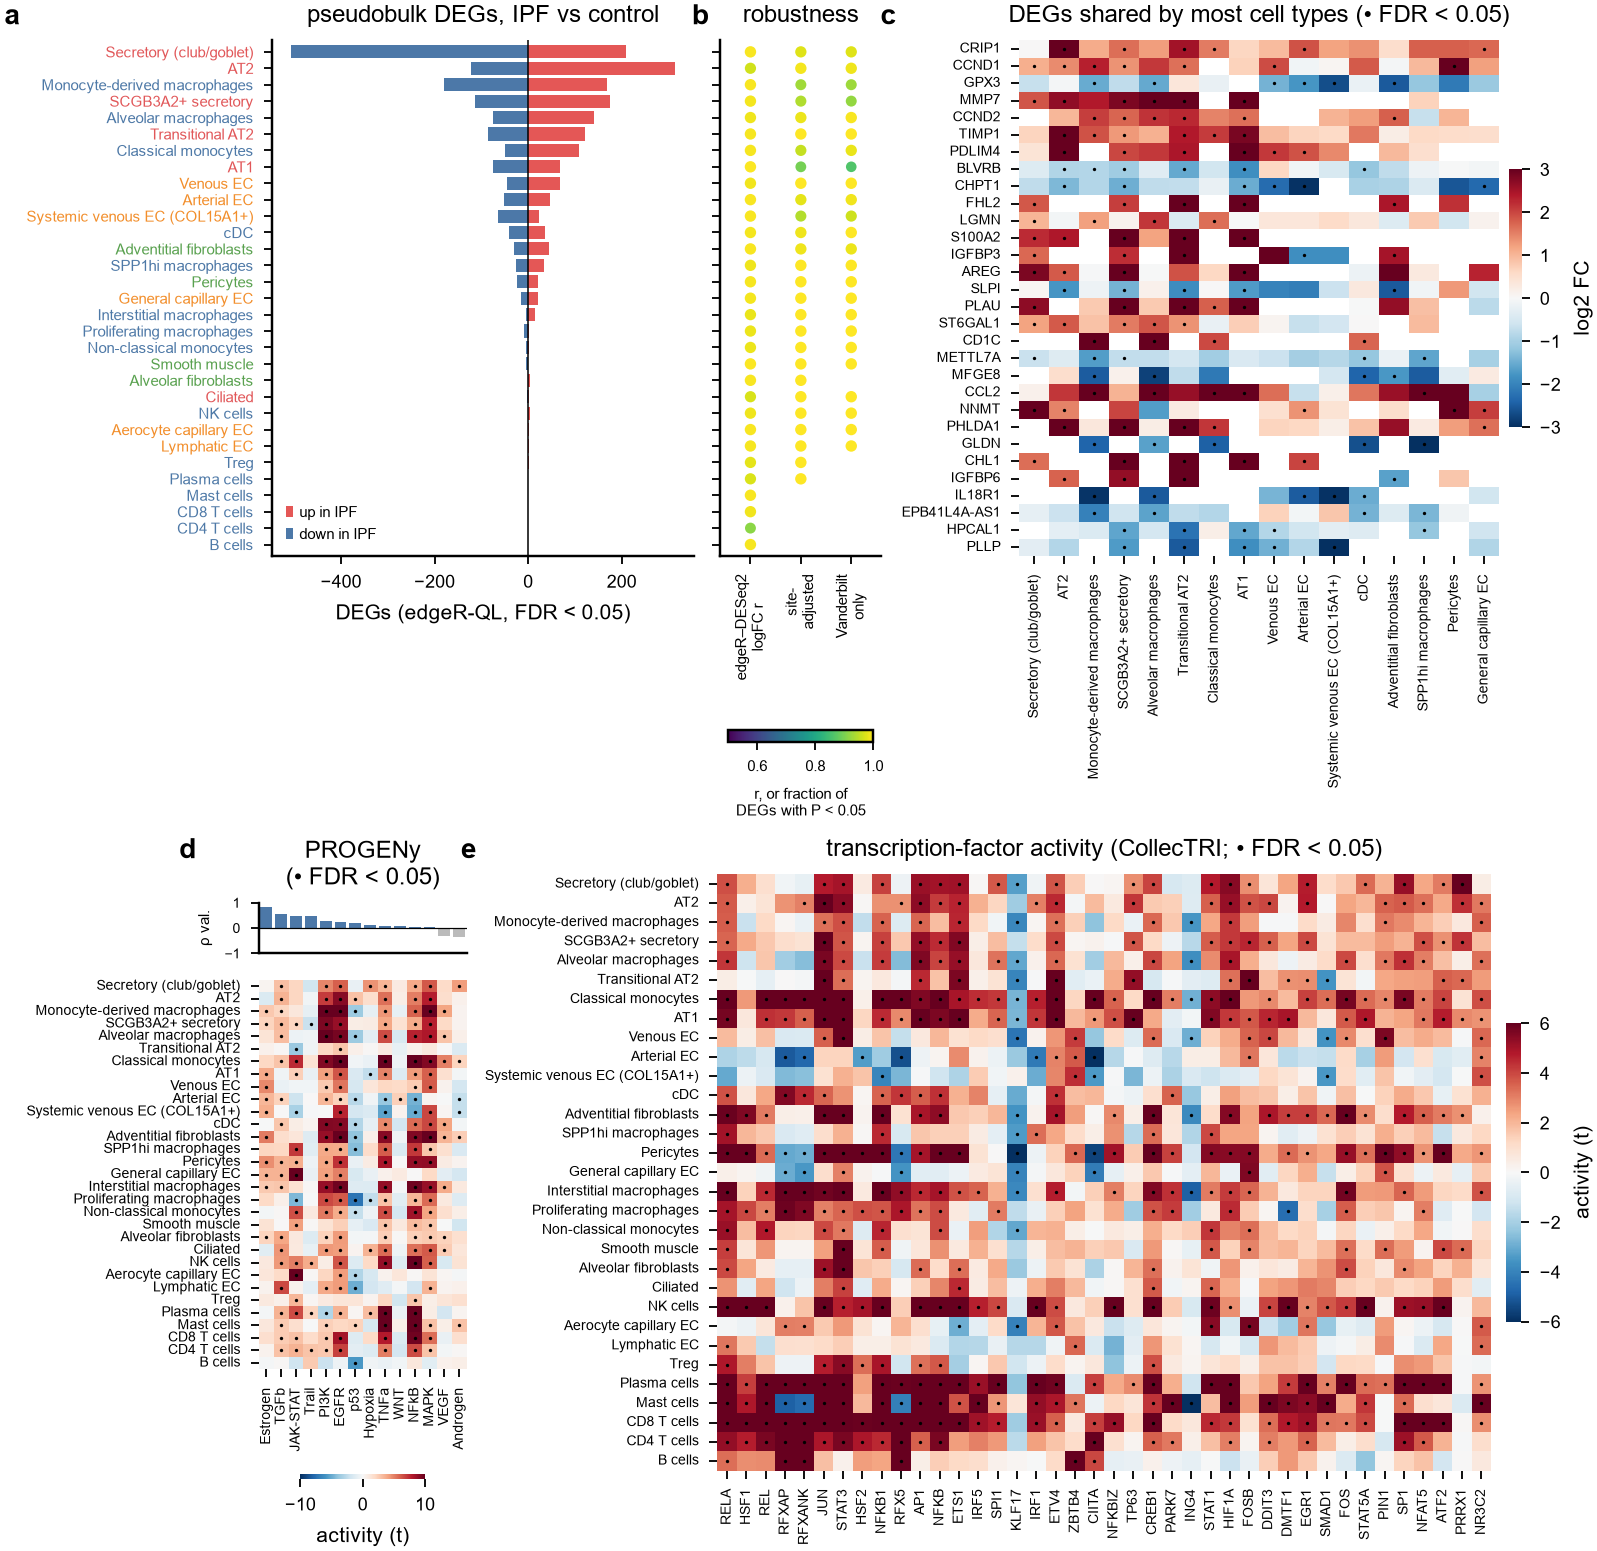

In [4]:
edger = pd.read_csv(P.tables / "07_de" / "edgeR_IPF_vs_control_all_celltypes.csv.gz")
agree = tab("07_de/edgeR_vs_DESeq2_agreement").set_index("celltype")
sens = tab("07_de/de_sensitivity_site").pivot(index="celltype", columns="analysis", values="replicated_P05")
recur = tab("07_de/deg_recurrence_across_celltypes")
prog, prog_padj = tab("08_pathways/progeny_scores", index_col=0), tab("08_pathways/progeny_padj", index_col=0)
tf, tf_padj = tab("08_pathways/collectri_scores", index_col=0), tab("08_pathways/collectri_padj", index_col=0)
pw_rep = tab("12_replication/progeny_replication_per_pathway").set_index("pathway")

s = edger[edger["FDR"] < cfg["de"]["fdr"]]
counts = pd.DataFrame({"up": s[s["logFC"] > 0].groupby("celltype").size(),
                       "down": s[s["logFC"] < 0].groupby("celltype").size()}).reindex(edger["celltype"].unique())
counts = counts.fillna(0).assign(total=lambda d: d.up + d.down).sort_values("total")

fig = plt.figure(figsize=figsize(W, 180), layout="constrained")
gs = fig.add_gridspec(2, 1, height_ratios=[1.15, 1])
top = gs[0].subgridspec(1, 3, width_ratios=[1.1, 0.42, 1.25])
bot = gs[1].subgridspec(1, 2, width_ratios=[0.8, 1.35])
ax_a, ax_b, ax_c = (fig.add_subplot(top[i]) for i in range(3))
inner = bot[0].subgridspec(2, 1, height_ratios=[0.13, 1])
ax_dr, ax_d, ax_e = fig.add_subplot(inner[0]), fig.add_subplot(inner[1]), fig.add_subplot(bot[1])

yy = np.arange(len(counts))
ax_a.barh(yy, counts["up"], color=CONDITION_COLORS["IPF"], label="up in IPF")
ax_a.barh(yy, -counts["down"], color=CONDITION_COLORS["Control"], label="down in IPF")
ax_a.axvline(0, lw=0.5, color="black")
ax_a.set_yticks(yy, counts.index, fontsize=5)
for lab_, t in zip(ax_a.get_yticklabels(), counts.index):
    lab_.set_color(COMPARTMENT_COLORS[comp_of[t]])
ax_a.set_ylim(-0.7, len(counts) - 0.3)
ax_a.set_xlabel("DEGs (edgeR-QL, FDR < 0.05)")
ax_a.set_title("pseudobulk DEGs, IPF vs control")
ax_a.legend(fontsize=5, frameon=False, loc="lower left")

rob = pd.DataFrame({"edgeR–DESeq2\nlogFC r": agree["pearson_logFC"],
                    "site-\nadjusted": sens["~ site + sex + diagnosis"],
                    "Vanderbilt\nonly": sens["Vanderbilt only"]}).reindex(counts.index)
for j, col in enumerate(rob.columns):
    ax_b.scatter(np.full(len(rob), j), yy, s=rob[col].fillna(0) * 14, c=rob[col], cmap="viridis", vmin=0.5, vmax=1,
                 lw=0)
ax_b.set_xticks(range(rob.shape[1]), rob.columns, rotation=90, fontsize=5)
ax_b.set_yticks(yy, [])
ax_b.set_ylim(-0.7, len(counts) - 0.3)
ax_b.set_xlim(-0.6, rob.shape[1] - 0.4)
ax_b.set_title("robustness")
sm = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0.5, 1), cmap="viridis")
cax = ax_b.inset_axes([0.05, -0.36, 0.9, 0.022])  # just under the rotated tick labels
fig.colorbar(sm, cax=cax, orientation="horizontal", label="r, or fraction of\nDEGs with P < 0.05")
cax.tick_params(labelsize=5)
cax.xaxis.label.set_size(5)

genes = recur.sort_values("n_celltypes", ascending=False)["gene"].head(30).tolist()
cts = counts.index[counts["total"] >= 30][::-1]
lfc = edger.pivot_table(index="gene", columns="celltype", values="logFC").reindex(index=genes, columns=cts)
fdr = edger.pivot_table(index="gene", columns="celltype", values="FDR").reindex(index=genes, columns=cts)
sns.heatmap(lfc, cmap="RdBu_r", center=0, vmin=-3, vmax=3, ax=ax_c, xticklabels=True, yticklabels=True,
            cbar_kws={"label": "log2 FC", "shrink": 0.5, "pad": 0.02})
yi, xi = np.where(fdr.to_numpy() < 0.05)
ax_c.scatter(xi + 0.5, yi + 0.5, s=1.2, color="black", lw=0)
ax_c.tick_params(labelsize=4.5)
ax_c.set_xlabel("")
ax_c.set_ylabel("")
ax_c.set_title("DEGs shared by most cell types (• FDR < 0.05)")

pw_order = pw_rep.sort_values("spearman_rho_across_celltypes", ascending=False).index
pcts = [t for t in counts.index[::-1] if t in prog.index]
sns.heatmap(prog.loc[pcts, pw_order], cmap="RdBu_r", center=0, vmin=-10, vmax=10, ax=ax_d, xticklabels=True,
            yticklabels=True, cbar_kws={"label": "activity (t)", "location": "bottom", "shrink": 0.6, "aspect": 25})
yi, xi = np.where(prog_padj.loc[pcts, pw_order].to_numpy() < 0.05)
ax_d.scatter(xi + 0.5, yi + 0.5, s=1.2, color="black", lw=0)
ax_d.tick_params(labelsize=4.5)
ax_d.set_xlabel("")
ax_d.set_ylabel("")
rho = pw_rep.loc[pw_order, "spearman_rho_across_celltypes"]
ax_dr.bar(np.arange(len(rho)) + 0.5, rho, width=0.8, color=np.where(rho > 0, "#4C78A8", "#BBBBBB"))
ax_dr.axhline(0, lw=0.4, color="black")
ax_dr.set_xlim(0, len(rho))
ax_dr.set_ylim(-1, 1)
ax_dr.set_xticks([])
ax_dr.set_yticks([-1, 0, 1])
ax_dr.tick_params(labelsize=4.5)
ax_dr.set_ylabel("ρ val.", fontsize=5)
ax_dr.set_title("PROGENy\n(• FDR < 0.05)")

nsig = (tf_padj < 0.05).sum()
tfs = (tf.abs() * (tf_padj < 0.05)).max().loc[nsig[nsig >= 6].index].sort_values(ascending=False).head(40).index
tcts = [t for t in counts.index[::-1] if t in tf.index]
mat = tf.loc[tcts, tfs]
sns.heatmap(mat, cmap="RdBu_r", center=0, vmin=-6, vmax=6, ax=ax_e, xticklabels=True, yticklabels=True,
            cbar_kws={"label": "activity (t)", "shrink": 0.5, "pad": 0.02})
yi, xi = np.where(tf_padj.loc[tcts, tfs].to_numpy() < 0.05)
ax_e.scatter(xi + 0.5, yi + 0.5, s=1.2, color="black", lw=0)
ax_e.tick_params(labelsize=4.5)
ax_e.set_ylabel("")
ax_e.set_title("transcription-factor activity (CollecTRI; • FDR < 0.05)")
panel_labels(fig, [ax_a, ax_b, ax_c, ax_dr, ax_e], "abcde")
save_figure(fig, "Fig3_de_pathways", FIG)
plt.show()

## Figure 4 · The alveolar epithelial trajectory to aberrant basaloid cells

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


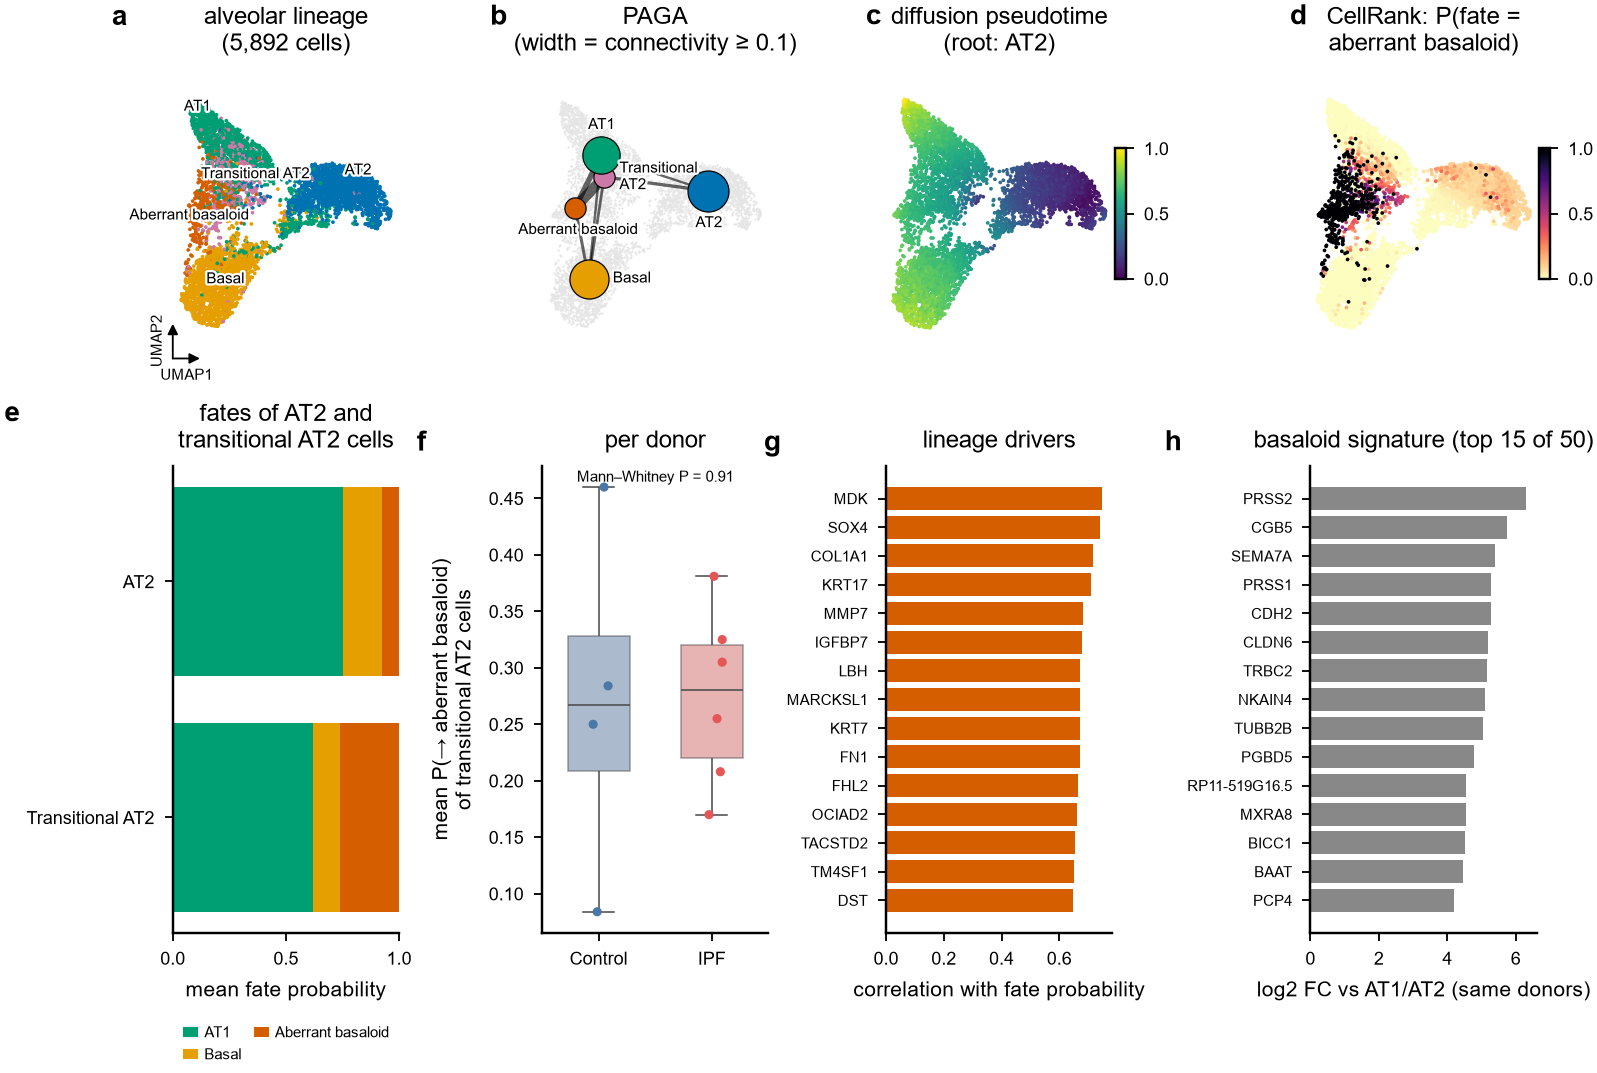

In [5]:
traj = ad.read_h5ad(P.processed / "epithelial_trajectory.h5ad", backed="r")
tobs = traj.obs[["cell_type", "diagnosis", "dpt_pseudotime", "fate_Aberrant basaloid", "fate_AT1"]].copy()
txy = np.asarray(traj.obsm["X_umap"])
traj.file.close()
lineage = list(LINEAGE_COLORS)
paga = tab("09_trajectory/paga_connectivities", index_col=0)
fates = tab("09_trajectory/fate_probabilities_mean_per_celltype", index_col=0)
tfd = tab("09_trajectory/transitional_fate_per_donor")
drv = tab("09_trajectory/lineage_drivers_aberrant_basaloid", index_col=0)
abs_sig = tab("09_trajectory/aberrant_basaloid_signature")

fig = plt.figure(figsize=figsize(W, 125), layout="constrained")
gs = fig.add_gridspec(2, 4, height_ratios=[0.62, 1])
axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
ax_a, ax_b, ax_c, ax_d = axes
embedding_scatter(ax_a, txy, tobs["cell_type"], palette=LINEAGE_COLORS, s=1.5)
label_centroids(ax_a, txy, tobs["cell_type"], fontsize=5, min_cells=50)
ax_a.set_title(f"alveolar lineage\n({len(tobs):,} cells)")
umap_axis_arrows(ax_a)

cent = {t: np.median(txy[(tobs["cell_type"] == t).to_numpy()], axis=0) for t in lineage}
size = tobs["cell_type"].value_counts()
ax_b.scatter(txy[:, 0], txy[:, 1], s=0.5, color="#E5E5E5", lw=0, rasterized=True)
for i, a in enumerate(lineage):
    for b_ in lineage[i + 1:]:
        w = paga.loc[a, b_]
        if w >= 0.1:
            ax_b.plot(*np.c_[cent[a], cent[b_]], color="black", lw=0.4 + 3 * w, alpha=0.6, zorder=1,
                      solid_capstyle="round")
# the nodes sit close together, so each label goes to a fixed side of its node (up, right or down)
side = {"AT1": (0, 1), "Transitional AT2": (1, 0), "AT2": (0, -1), "Aberrant basaloid": (0, -1), "Basal": (1, 0)}
for t in lineage:
    s_ = size[t] / 10
    ax_b.scatter(*cent[t], s=s_, color=LINEAGE_COLORS[t], edgecolor="black", lw=0.4, zorder=2)
    dx, dy = side[t]
    r = np.sqrt(s_) / 2 + 1.5
    ax_b.annotate(t.replace("Transitional ", "Transitional\n"), cent[t], xytext=(dx * r, dy * r),
                  textcoords="offset points", fontsize=5, zorder=3,
                  ha="left" if dx else "center", va={1: "bottom", 0: "center", -1: "top"}[dy],
                  path_effects=[patheffects.withStroke(linewidth=1.5, foreground="white")])
pad = 0.05 * np.ptp(txy, axis=0)
ax_b.set_xlim(txy[:, 0].min() - pad[0], txy[:, 0].max() + pad[0])
ax_b.set_ylim(txy[:, 1].min() - pad[1], txy[:, 1].max() + pad[1])
ax_b.set_aspect("equal", adjustable="datalim")
ax_b.axis("off")
ax_b.set_title("PAGA\n(width = connectivity ≥ 0.1)")

for ax, col, cmap, title in [(ax_c, "dpt_pseudotime", "viridis", "diffusion pseudotime\n(root: AT2)"),
                             (ax_d, "fate_Aberrant basaloid", "magma_r", "CellRank: P(fate =\naberrant basaloid)")]:
    sca = embedding_scatter(ax, txy, tobs[col].astype(float), cmap=cmap, s=1.5, order="value", vmin=0, vmax=1)
    fig.colorbar(sca, ax=ax, shrink=0.45, aspect=12, pad=0.01)
    ax.set_title(title)

ax_e, ax_f, ax_g, ax_h = (fig.add_subplot(gs[1, i]) for i in range(4))
f = fates[["AT1", "Basal", "Aberrant basaloid"]]
left = np.zeros(len(f))
for t in f.columns:
    ax_e.barh(f.index, f[t], left=left, color=LINEAGE_COLORS[t], label=t)
    left += f[t].to_numpy()
ax_e.invert_yaxis()
ax_e.set_xlim(0, 1)
ax_e.set_xticks([0, 0.5, 1])
ax_e.set_xlabel("mean fate probability")
ax_e.set_title("fates of AT2 and\ntransitional AT2 cells")
ax_e.legend(fontsize=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, handlelength=1,
            columnspacing=0.8)

pval = mannwhitneyu(*[tfd.loc[tfd["diagnosis"] == g, "fate_basaloid"] for g in ["Control", "IPF"]]).pvalue
sns.boxplot(tfd, x="diagnosis", y="fate_basaloid", order=["Control", "IPF"], hue="diagnosis", palette=CONDITION_COLORS,
            ax=ax_f, fliersize=0, linewidth=0.5, width=0.55, legend=False, boxprops={"alpha": 0.5})
sns.stripplot(tfd, x="diagnosis", y="fate_basaloid", order=["Control", "IPF"], hue="diagnosis",
              palette=CONDITION_COLORS, ax=ax_f, size=3, jitter=0.12, legend=False)
ax_f.set_xlabel("")
ax_f.set_ylabel("mean P(→ aberrant basaloid)\nof transitional AT2 cells")
ax_f.set_title("per donor")
ax_f.text(0.5, 0.99, f"Mann–Whitney P = {pval:.2f}", transform=ax_f.transAxes, ha="center", va="top", fontsize=5)

top_drv = drv["Aberrant basaloid_corr"].sort_values(ascending=False).head(15)[::-1]
ax_g.barh(top_drv.index, top_drv.to_numpy(), color=LINEAGE_COLORS["Aberrant basaloid"])
ax_g.set_xlabel("correlation with fate probability")
ax_g.set_title("lineage drivers")
ax_g.tick_params(axis="y", labelsize=5)

top_sig = abs_sig.sort_values("logFC", ascending=False).head(15)[::-1]
ax_h.barh(top_sig["gene"], top_sig["logFC"], color="#888888")
ax_h.set_xlabel("log2 FC vs AT1/AT2 (same donors)")
ax_h.set_title(f"basaloid signature (top 15 of {len(abs_sig)})")
ax_h.tick_params(axis="y", labelsize=5)
panel_labels(fig, [ax_a, ax_b, ax_c, ax_d, ax_e, ax_f, ax_g, ax_h], "abcdefgh")
save_figure(fig, "Fig4_epithelial_trajectory", FIG)
plt.show()

## Figure 5 · Cell–cell communication
Interactions are ligand–receptor pairs whose ligand is up in the sender and whose
receptor is up in the receiver (pseudobulk statistics, both partners expressed
in ≥ 10 % of cells; Notebook 10).

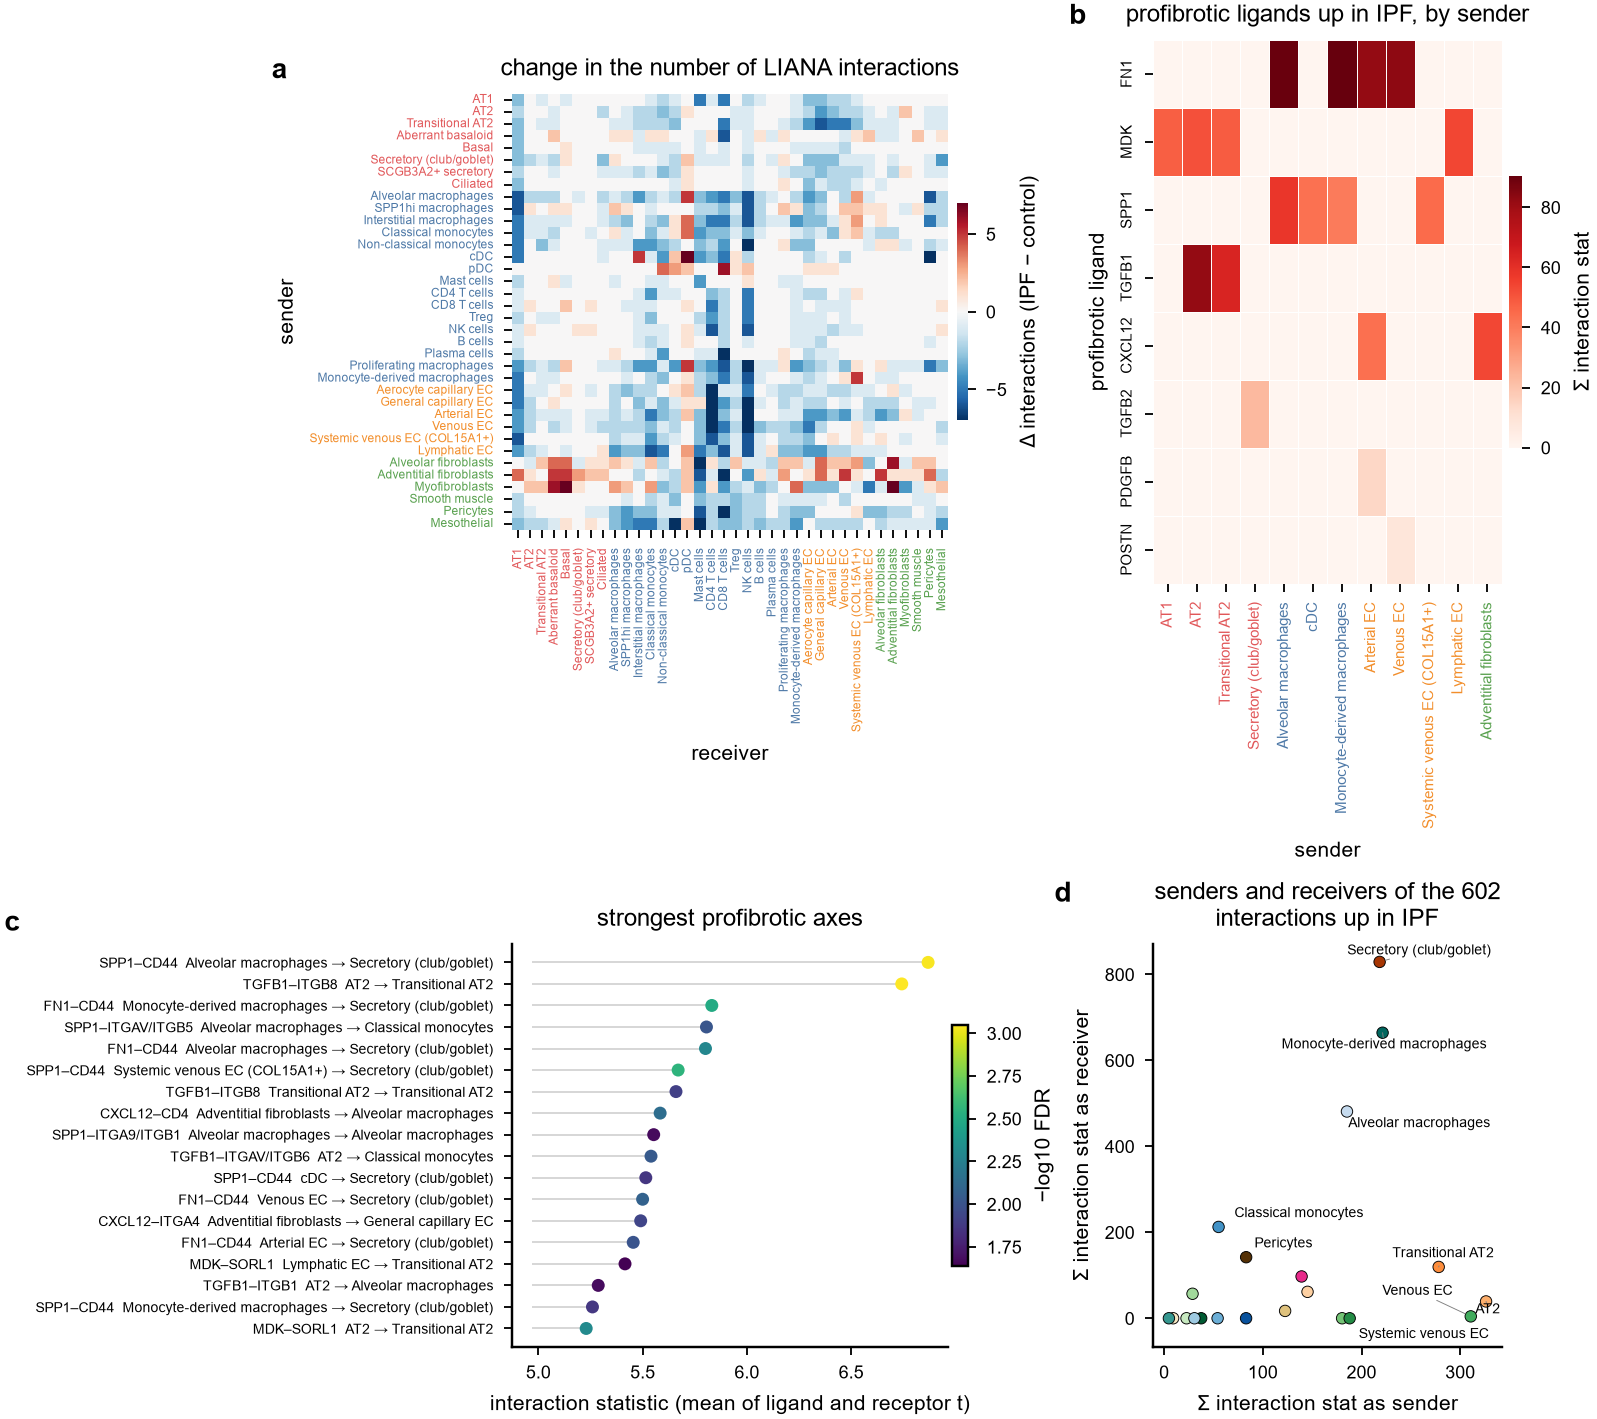

In [6]:
dn = tab("10_communication/n_interactions_IPF_minus_Control", index_col=0).reindex(index=grouped, columns=grouped)
up = tab("10_communication/differential_lr_both_up")
cand = tab("10_communication/candidate_profibrotic_axes")

fig = plt.figure(figsize=figsize(W, 165), layout="constrained")
gs = fig.add_gridspec(2, 2, height_ratios=[1.35, 1], width_ratios=[1.25, 1])
ax_a = fig.add_subplot(gs[0, 0])
lim = np.nanpercentile(np.abs(dn.to_numpy()), 99)
sns.heatmap(dn, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, ax=ax_a, xticklabels=True, yticklabels=True,
            square=True, cbar_kws={"label": "Δ interactions (IPF − control)", "shrink": 0.4, "pad": 0.02})
ax_a.tick_params(labelsize=4)
for lab_ in ax_a.get_xticklabels() + ax_a.get_yticklabels():
    lab_.set_color(COMPARTMENT_COLORS[comp_of[lab_.get_text()]])
ax_a.set_xlabel("receiver")
ax_a.set_ylabel("sender")
ax_a.set_title("change in the number of LIANA interactions")

ax_b = fig.add_subplot(gs[0, 1])
lig = cand.pivot_table(index="ligand_complex", columns="source", values="interaction_stat", aggfunc="sum").fillna(0)
lig = lig.loc[lig.sum(axis=1).sort_values(ascending=False).index, [t for t in grouped if t in lig.columns]]
sns.heatmap(lig, cmap="Reds", ax=ax_b, xticklabels=True, yticklabels=True, linewidths=0.2, linecolor="white",
            cbar_kws={"label": "Σ interaction stat", "shrink": 0.5, "pad": 0.02})
ax_b.tick_params(labelsize=5)
for lab_ in ax_b.get_xticklabels():
    lab_.set_color(COMPARTMENT_COLORS[comp_of[lab_.get_text()]])
ax_b.set_xlabel("sender")
ax_b.set_ylabel("profibrotic ligand")
ax_b.set_title("profibrotic ligands up in IPF, by sender")

ax_c = fig.add_subplot(gs[1, 0])
c = cand.sort_values("interaction_stat", ascending=False).drop_duplicates(["source", "target", "ligand_complex"])
c = c.head(18)[::-1]
yy = np.arange(len(c))
sca = ax_c.scatter(c["interaction_stat"], yy, s=18, c=-np.log10(c["interaction_padj"]), cmap="viridis", lw=0)
ax_c.hlines(yy, c["interaction_stat"].min() * 0.95, c["interaction_stat"], color="#CCCCCC", lw=0.5, zorder=0)
ax_c.set_yticks(yy, [f"{r.ligand_complex}–{r.receptor_complex.replace('_', '/')}  {r.source} → {r.target}"
                     for r in c.itertuples()], fontsize=4.5)
ax_c.set_xlabel("interaction statistic (mean of ligand and receptor t)")
ax_c.set_title("strongest profibrotic axes")
fig.colorbar(sca, ax=ax_c, shrink=0.6, aspect=15, pad=0.01, label="−log10 FDR")

ax_d = fig.add_subplot(gs[1, 1])
sr = pd.DataFrame({"send": up.groupby("source")["interaction_stat"].sum(),
                   "recv": up.groupby("target")["interaction_stat"].sum()}).fillna(0)
ax_d.scatter(sr["send"], sr["recv"], s=14, c=[colors[t] for t in sr.index], edgecolor="black", lw=0.3)
lab = sr[(sr["send"] >= sr["send"].nlargest(6).min()) | (sr["recv"] >= sr["recv"].nlargest(6).min())]
texts = [ax_d.text(r.send, r.recv, r.Index.replace(" (COL15A1+)", ""), fontsize=4.5) for r in lab.itertuples()]
ax_d.set_ylim(-0.08 * sr["recv"].max(), None)
adjust_text(texts, x=sr["send"].to_numpy(), y=sr["recv"].to_numpy(), ax=ax_d, expand=(1.3, 1.8),
            arrowprops={"arrowstyle": "-", "lw": 0.3, "color": "grey"})
ax_d.set_xlabel("Σ interaction stat as sender")
ax_d.set_ylabel("Σ interaction stat as receiver")
ax_d.set_title(f"senders and receivers of the {len(up):,}\ninteractions up in IPF")
panel_labels(fig, [ax_a, ax_b, ax_c, ax_d], "abcd")
save_figure(fig, "Fig5_communication", FIG)
plt.show()

## Figure 6 · Replication in an independent cohort (GSE136831)

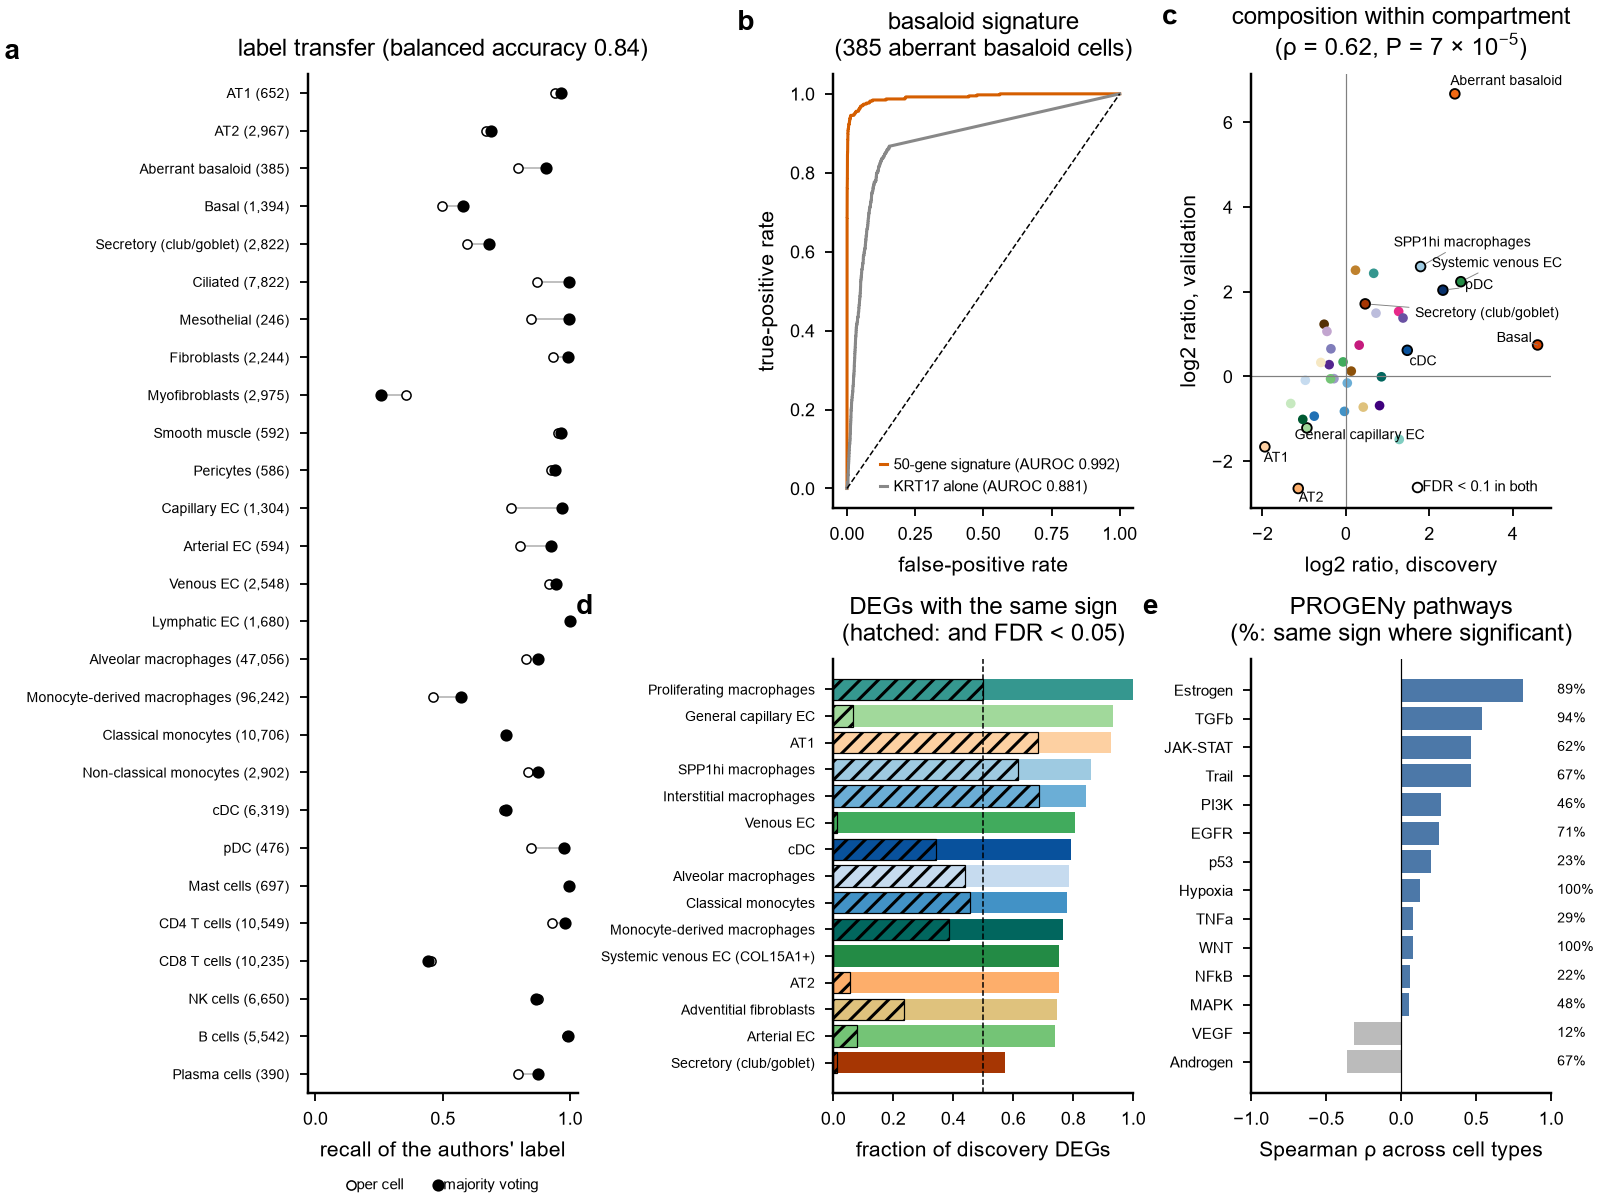

In [7]:
rec6 = tab("12_replication/label_transfer_recall_per_type", index_col=0)
agr = tab("12_replication/label_transfer_agreement", index_col=0)
bsc = tab("12_replication/basaloid_signature_scores_epithelial")
cmp6 = tab("12_replication/composition_replication")
rep = tab("12_replication/de_replication_per_celltype")
pwr = tab("12_replication/progeny_replication_per_pathway")

fig = plt.figure(figsize=figsize(W, 140), layout="constrained")
gs = fig.add_gridspec(2, 3, width_ratios=[0.9, 1, 1])
ax_a = fig.add_subplot(gs[:, 0])
yy = np.arange(len(rec6))
ax_a.hlines(yy, rec6["per cell"], rec6["majority voting"], color="#BBBBBB", lw=0.6)
ax_a.scatter(rec6["per cell"], yy, s=9, facecolor="white", edgecolor="black", lw=0.5, zorder=3, label="per cell")
ax_a.scatter(rec6["majority voting"], yy, s=9, color="black", zorder=3, label="majority voting")
ax_a.set_yticks(yy, [f"{t} ({int(n):,})" for t, n in zip(rec6.index, rec6["n_cells"])], fontsize=4.5)
ax_a.set_ylim(len(rec6) - 0.5, -0.5)
ax_a.set_xlim(-0.03, 1.03)
ax_a.set_xlabel("recall of the authors' label")
mv = agr.loc["majority voting"]
ax_a.set_title(f"label transfer (balanced accuracy {mv['balanced_accuracy']:.2f})")
ax_a.legend(fontsize=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2,
            handletextpad=0.1)

ax_b = fig.add_subplot(gs[0, 1])
yb = (bsc["author_celltype"] == "Aberrant_Basaloid").to_numpy()
for col, name, color in [("signature_score", "50-gene signature", LINEAGE_COLORS["Aberrant basaloid"]),
                         ("KRT17", "KRT17 alone", "#888888")]:
    fpr, tpr, _ = roc_curve(yb, bsc[col])
    ax_b.plot(fpr, tpr, color=color, lw=1, label=f"{name} (AUROC {roc_auc_score(yb, bsc[col]):.3f})")
ax_b.plot([0, 1], [0, 1], ls="--", lw=0.5, color="black")
ax_b.set_xlabel("false-positive rate")
ax_b.set_ylabel("true-positive rate")
ax_b.legend(fontsize=5, frameon=False, loc="lower right")
ax_b.set_title(f"basaloid signature\n({yb.sum():,} aberrant basaloid cells)")

ax_c = fig.add_subplot(gs[0, 2])
d = cmp6[cmp6["scope"] != "all cells"]
rho, p = spearmanr(d["log2_prop_ratio_disc"], d["log2_prop_ratio_val"])
both = (d["FDR_disc"] < 0.1) & (d["FDR_val"] < 0.1)
ax_c.axhline(0, lw=0.4, color="grey")
ax_c.axvline(0, lw=0.4, color="grey")
ax_c.scatter(d["log2_prop_ratio_disc"], d["log2_prop_ratio_val"], s=10, c=[colors.get(t, "grey") for t in d["celltype"]],
             edgecolor=np.where(both, "black", "none"), lw=0.6)
lab = d[both | d["celltype"].isin(["Aberrant basaloid", "Basal", "AT1"])]
texts = [ax_c.text(r.log2_prop_ratio_disc, r.log2_prop_ratio_val, r.celltype.replace(" (COL15A1+)", ""), fontsize=4.5)
         for r in lab.itertuples()]
adjust_text(texts, x=d["log2_prop_ratio_disc"].to_numpy(), y=d["log2_prop_ratio_val"].to_numpy(), ax=ax_c,
            expand=(1.3, 1.8), arrowprops={"arrowstyle": "-", "lw": 0.3, "color": "grey"})
ax_c.scatter([], [], s=10, facecolor="white", edgecolor="black", lw=0.6, label="FDR < 0.1 in both")
ax_c.legend(fontsize=5, frameon=False, loc="lower right", handletextpad=0.1)
ax_c.set_xlabel("log2 ratio, discovery")
ax_c.set_ylabel("log2 ratio, validation")
ax_c.set_title(f"composition within compartment\n(ρ = {rho:.2f}, P = {fmt_p(p)})")

ax_d = fig.add_subplot(gs[1, 1])
r = rep.sort_values("sign_concordance")
yy = np.arange(len(r))
ax_d.barh(yy, r["sign_concordance"], color=[colors.get(t, "grey") for t in r["celltype"]])
ax_d.barh(yy, r["replicated_FDR05_same_sign"], color="none", edgecolor="black", hatch="////", lw=0.4)
ax_d.axvline(0.5, ls="--", lw=0.5, color="black")
ax_d.set_yticks(yy, r["celltype"], fontsize=4.5)
ax_d.set_xlim(0, 1)
ax_d.set_xlabel("fraction of discovery DEGs")
ax_d.set_title("DEGs with the same sign\n(hatched: and FDR < 0.05)")

ax_e = fig.add_subplot(gs[1, 2])
r = pwr.sort_values("spearman_rho_across_celltypes")
ax_e.barh(r["pathway"], r["spearman_rho_across_celltypes"],
          color=np.where(r["spearman_rho_across_celltypes"] > 0, "#4C78A8", "#BBBBBB"))
for i, v in enumerate(r["sign_agreement_FDR05_discovery"]):
    if pd.notna(v):
        ax_e.text(1.02, i, f"{v:.0%}", va="center", fontsize=4.5, transform=ax_e.get_yaxis_transform())
ax_e.axvline(0, lw=0.4, color="black")
ax_e.set_xlim(-1, 1)
ax_e.tick_params(axis="y", labelsize=5)
ax_e.set_xlabel("Spearman ρ across cell types")
ax_e.set_title("PROGENy pathways\n(%: same sign where significant)")
panel_labels(fig, [ax_a, ax_b, ax_c, ax_d, ax_e], "abcde")
save_figure(fig, "Fig6_replication", FIG)
plt.show()